**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [ ]:
flood = 0
jobs = [
    ("md", f"net_v3_{flood}per_v2"),
    ("ocsvm", f"net_v3_{flood}per_w_v2"),

]

def load_job(metodo, job_name):
    results_dir = f"/tmp/anomaly_results_{metodo}_{job_name}"      
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_{metodo}_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []
all_rules = {}

for metodo, job_name in jobs:
    results, df = load_job(metodo, job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "metodo": metodo,
        "job_name": job_name,
        "min_flood_area": results.get("min_flood_area"),
        "n_fit": results.get("n_fit"), "n_thr": results.get("n_thr"), "n_normali": results.get("n_normali"), "n_anomale": results.get("n_anomale"),
        "score_normali": f"{score_normal.mean():.2f} ± {score_normal.std():.2f}",
        "score_anomale": f"{score_anom.mean():.2f} ± {score_anom.std():.2f}",
        "auroc": results.get("auroc"),   
    })
    all_rules[(metodo, job_name)] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index(["metodo", "job_name"])
df_rules = pd.concat(all_rules, names=["metodo", "job_name", "regola"])

df_summary

,,min_flood_area,n_fit,n_thr,n_normali,n_anomale,score_normali,score_anomale,auroc
metodo,job_name,,,,,,,,
md,net_v3_0per_v2,0.0,2072,500,2402,2402,-301.62 ± 337.71,-399.28 ± 2141.52,0.709341
ocsvm,net_v3_0per_w_v2,0.0,2072,500,2402,2402,1.23 ± 1.42,0.17 ± 1.46,0.709084


In [8]:
df_rules

soglia      TP     FP      FN      TN  \
metodo job_name         regola                                              
md     net_v3_0per_v2   FA 5%  -488.132888   241.0   84.0  2161.0  2318.0   
                        FA 10% -394.072959   611.0  195.0  1791.0  2207.0   
                        FA 15% -363.432358   831.0  289.0  1571.0  2113.0   
                        FA 20% -336.147755  1079.0  437.0  1323.0  1965.0   
                        FA 25% -319.196318  1240.0  558.0  1162.0  1844.0   
                        FA 30% -305.824734  1377.0  649.0  1025.0  1753.0   
ocsvm  net_v3_0per_w_v2 FA 5%    -1.621194   276.0   88.0  2126.0  2314.0   
                        FA 10%   -0.670833   657.0  206.0  1745.0  2196.0   
                        FA 15%   -0.281156   862.0  314.0  1540.0  2088.0   
                        FA 20%    0.059512  1069.0  429.0  1333.0  1973.0   
                        FA 25%    0.389950  1266.0  562.0  1136.0  1840.0   
                        FA 30%    0.594179  1386.0  661.0  1016.0  1741.0   

                                 FA_rate   MA_rate       REC      PREC  \
metodo job_name         regola                                           
md     net_v3_0per_v2   FA 5%   0.034971  0.899667  0.100333  0.741538   
                        FA 10%  0.081182  0.745629  0.254371  0.758065   
                        FA 15%  0.120316  0.654038  0.345962  0.741964   
                        FA 20%  0.181932  0.550791  0.449209  0.711741   
                        FA 25%  0.232306  0.483764  0.516236  0.689655   
                        FA 30%  0.270192  0.426728  0.573272  0.679664   
ocsvm  net_v3_0per_w_v2 FA 5%   0.036636  0.885096  0.114904  0.758242   
                        FA 10%  0.085762  0.726478  0.273522  0.761298   
                        FA 15%  0.130724  0.641132  0.358868  0.732993   
                        FA 20%  0.178601  0.554954  0.445046  0.713618   
                        FA 25%  0.233972  0.472939  0.527061  0.692560   
                        FA 30%  0.275187  0.422981  0.577019  0.677088   

                                      F1  
metodo job_name         regola            
md     net_v3_0per_v2   FA 5%   0.176751  
                        FA 10%  0.380923  
                        FA 15%  0.471891  
                        FA 20%  0.550791  
                        FA 25%  0.590476  
                        FA 30%  0.621951  
ocsvm  net_v3_0per_w_v2 FA 5%   0.199566  
                        FA 10%  0.402450  
                        FA 15%  0.481833  
                        FA 20%  0.548205  
                        FA 25%  0.598582  
                        FA 30%  0.623061

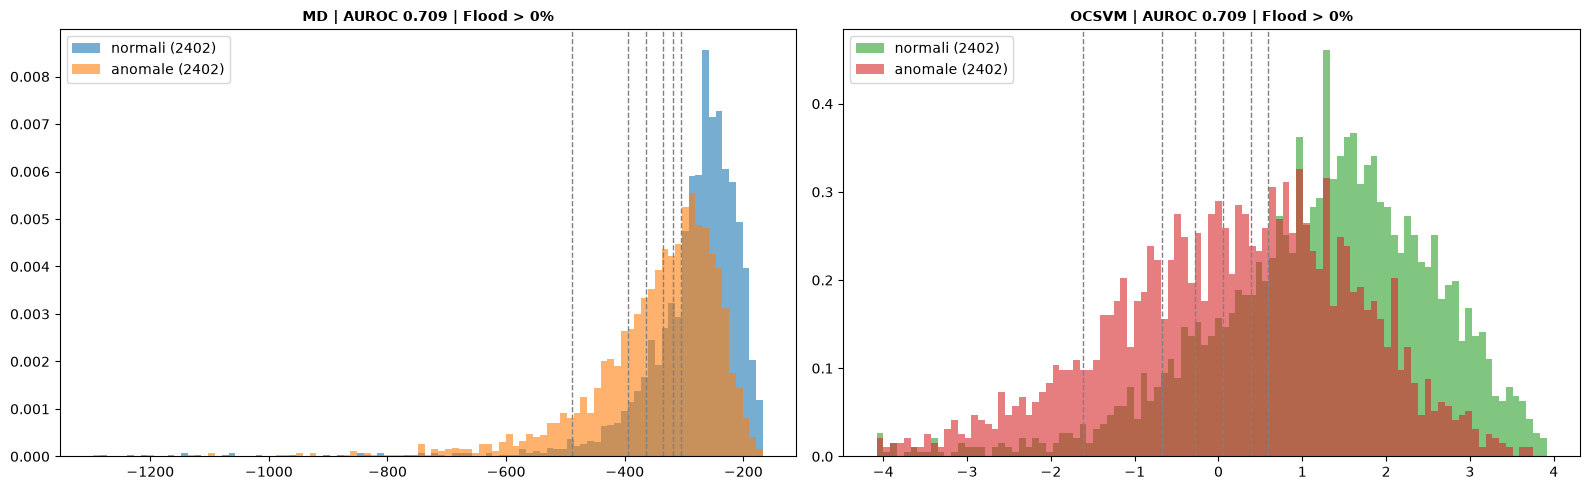

In [9]:
def plot_hist(ax, metodo, job_name, results, df, colori=("tab:blue", "tab:orange")):
    col_normal, col_anom = colori

    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, color=col_normal, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, color=col_anom, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        etichetta = nome.split("(")[-1].rstrip(")")
        for chiave in ("soglia", "soglia_low", "soglia_high"):
            s = r.get(chiave)
            if s is not None and lo <= s <= hi:
                ax.axvline(x=s, color="gray", linestyle="--", linewidth=1)
                ax.text(s, ax.get_ylim()[1] * 0.97, "", rotation=90, va="top", ha="right", fontsize=8)

    auroc = results.get("auroc", results.get("auroc_cos_sim_low_anom"))
    ax.legend(loc="upper left")
    ax.set_title(f"{metodo.upper()} | AUROC {auroc:.3f} | Flood > {flood}%", fontsize=10, fontweight="bold")


n_cols = 2
n_rows = int(np.ceil(len(jobs) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

meta = len(jobs) // 2

for i, (ax, (metodo, job_name)) in enumerate(zip(axes.flat, jobs)):
    colori = ("tab:blue", "tab:orange") if i < meta else ("tab:green", "tab:red")
    results, df = load_job(metodo, job_name)
    plot_hist(ax, metodo, job_name, results, df, colori=colori)

for ax in axes.flat[len(jobs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

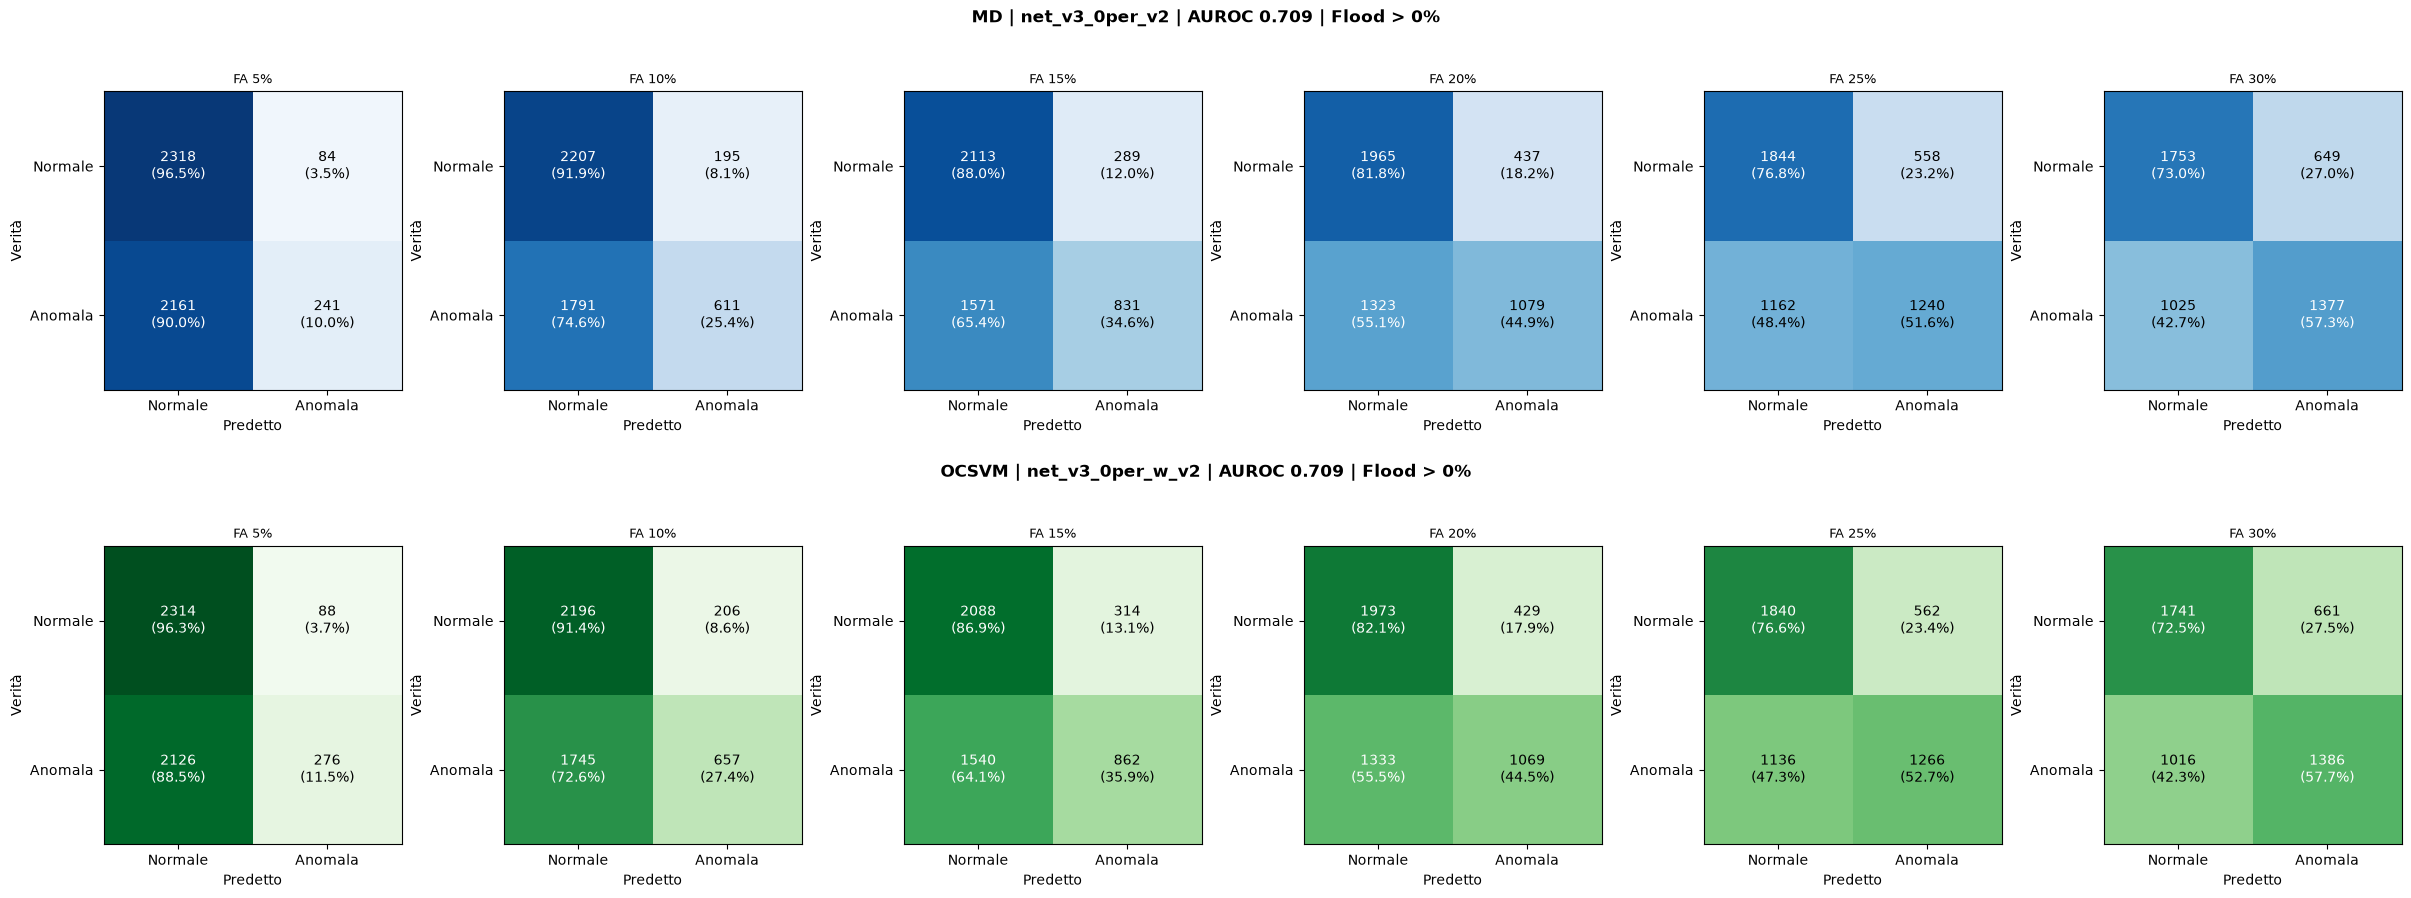

In [10]:
def plot_confusion_row(sfig, metodo, job_name, results, n_cols, cmap="Blues"):
    rules = results["rules"]
    auroc = results.get("auroc", results.get("auroc_cos_sim_low_anom"))
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap=cmap, vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"{metodo.upper()} | {job_name} | AUROC {auroc:.3f} | Flood > {flood:.0f}%", fontsize=12, fontweight="bold")


loaded = [(metodo, job_name, load_job(metodo, job_name)[0]) for metodo, job_name in jobs]
n_rows = len(loaded)
n_cols = max(len(res["rules"]) for _, _, res in loaded)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1)

meta = n_rows // 2

for i, (sfig, (metodo, job_name, results)) in enumerate(zip(subfigs, loaded)):
    cmap = "Blues" if i < meta else "Greens"
    plot_confusion_row(sfig, metodo, job_name, results, n_cols, cmap=cmap)

plt.show()

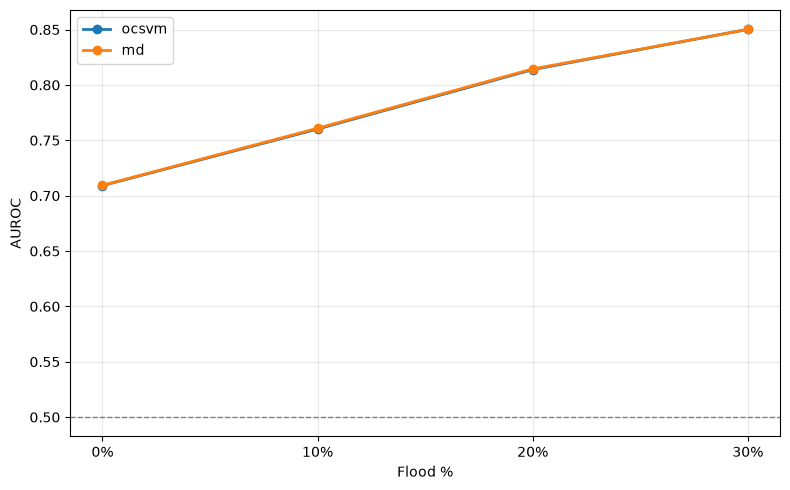

,ocsvm,md
min_flood_area,,
0,0.709084,0.709341
10,0.760172,0.760864
20,0.813847,0.814490
30,0.850195,0.850116


In [16]:
floods = [0, 10, 20, 30]

metodi = [
    ("ocsvm", "ocsvm", lambda f: f"net_v3_{f}per_w_v2"),
    ("md", "md",    lambda f: f"net_v3_{f}per_v2"),
]

auroc_table = {}            
for etichetta, metodo, nome in metodi:
    valori = []
    for f in floods:
        try:
            results, _ = load_job(metodo, nome(f))
            valori.append(results.get("auroc"))
        except Exception as e:
            print(f"EXC -> {metodo}_{nome(f)}: {e}")
            valori.append(np.nan)                                
    auroc_table[etichetta] = valori

df_auroc = pd.DataFrame(auroc_table, index=floods)
df_auroc.index.name = "min_flood_area"

fig, ax = plt.subplots(figsize=(8, 5))
for etichetta in df_auroc.columns:
    ax.plot(df_auroc.index, df_auroc[etichetta], marker="o", linewidth=2, label=etichetta)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)         
ax.set_xticks(floods)
ax.set_xticklabels([f"{f}%" for f in floods])
ax.set_xlabel("Flood %")
ax.set_ylabel("AUROC")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

df_auroc